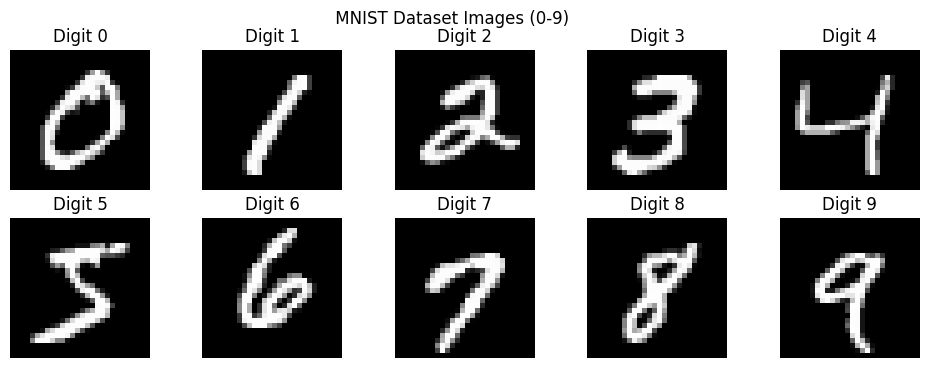

Epoch: 1 completed
Epoch: 2 completed
Epoch: 3 completed
Epoch: 4 completed
Epoch: 5 completed


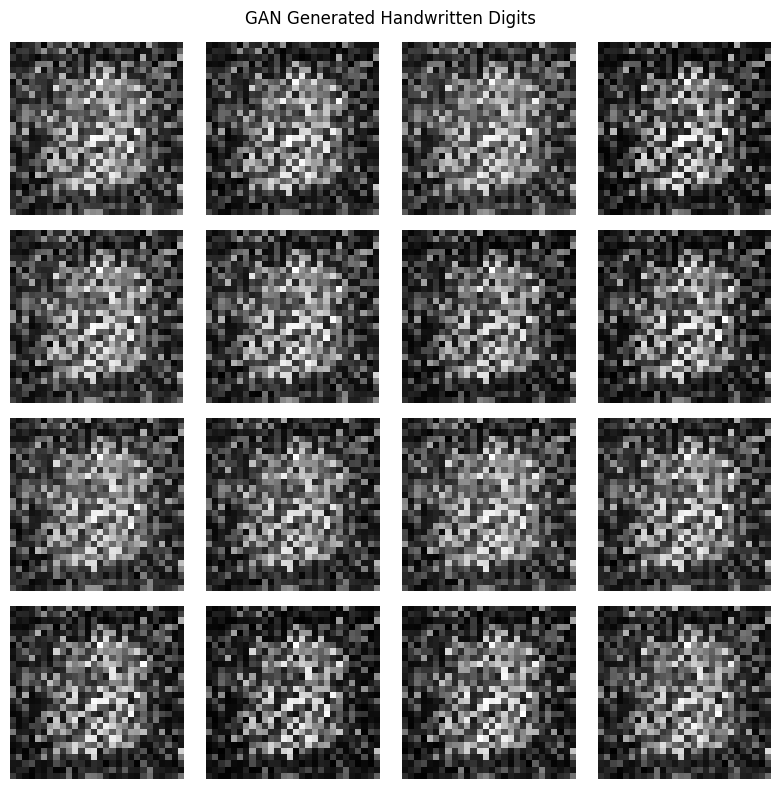

In [4]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

(x_train, y_train), (_, _) = tf.keras.datasets.mnist.load_data()

plt.figure(figsize=(12, 4))

for digit in range(10):
    index = np.where(y_train == digit)[0][0]
    plt.subplot(2, 5, digit + 1)
    plt.imshow(x_train[index], cmap='gray')
    plt.title("Digit " + str(digit))
    plt.axis('off')

plt.suptitle(" MNIST Dataset Images (0-9)")

plt.show()

x_train = (x_train.astype('float32') - 127.5) / 127.5
x_train = np.expand_dims(x_train, axis=-1)

dataset = tf.data.Dataset.from_tensor_slices(x_train).shuffle(60000).batch(256)

generator = tf.keras.Sequential([
    tf.keras.layers.Dense(128, activation='relu', input_shape=(100,)),
    tf.keras.layers.Dense(256, activation='relu'),
    tf.keras.layers.Dense(784, activation='tanh'),
    tf.keras.layers.Reshape((28, 28, 1))
])

discriminator = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(28, 28, 1)),
    tf.keras.layers.Dense(256),
    tf.keras.layers.LeakyReLU(negative_slope=0.2),
    tf.keras.layers.Dense(128),
    tf.keras.layers.LeakyReLU(negative_slope=0.2),
    tf.keras.layers.Dense(1)
])

cross_entropy = tf.keras.losses.BinaryCrossentropy(from_logits=True)

generator_optimizer = tf.keras.optimizers.Adam(0.0002)
discriminator_optimizer = tf.keras.optimizers.Adam(0.0002)

@tf.function
def train_step(images):
    noise = tf.random.normal([tf.shape(images)[0], 100])

    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:
        generated_images = generator(noise, training=True)

        real_output = discriminator(images, training=True)
        fake_output = discriminator(generated_images, training=True)

        gen_loss = cross_entropy(tf.ones_like(fake_output), fake_output)

        real_loss = cross_entropy(tf.ones_like(real_output), real_output)
        fake_loss = cross_entropy(tf.zeros_like(fake_output), fake_output)
        disc_loss = real_loss + fake_loss

    gen_gradients = gen_tape.gradient(gen_loss, generator.trainable_variables)
    disc_gradients = disc_tape.gradient(disc_loss, discriminator.trainable_variables)

    generator_optimizer.apply_gradients(zip(gen_gradients, generator.trainable_variables))
    discriminator_optimizer.apply_gradients(zip(disc_gradients, discriminator.trainable_variables))

for epoch in range(5):
    for images in dataset:
        train_step(images)
    print("Epoch:", epoch + 1, "completed")

noise = tf.random.normal([16, 100])
generated_images = generator(noise, training=False)

plt.figure(figsize=(8, 8))

for i in range(16):
    plt.subplot(4, 4, i + 1)
    plt.imshow(generated_images[i, :, :, 0] * 127.5 + 127.5, cmap='gray')
    plt.axis('off')

plt.suptitle("GAN Generated Handwritten Digits")
plt.tight_layout()
plt.show()